In [ ]:
# installs for kaggle env difficulties 

!apt-get update && apt-get install -y swig build-essential
!pip install --upgrade setuptools wheel
!pip install --no-build-isolation gymnasium[box2d] stable-baselines3[extra]

In [3]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
import os
import gymnasium as gym

from stable_baselines3 import PPO
from stable_baselines3.common.logger import configure
from stable_baselines3.common.vec_env import SubprocVecEnv
import pandas as pd 
import torch
from stable_baselines3.common.results_plotter import plot_results
from stable_baselines3.common import results_plotter
import matplotlib as plt
import numpy as np
import pprint
import json
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import CheckpointCallback


In [5]:
model_dir = './ppo_baseline/0.01_ent'

log_dir = f'{model_dir}/env_logs/'
model_log_dir = f'{model_dir}/model_logs'
model_file = f'{model_dir}/ppo_racing'
results_dir = f'./racing/results/'

num_timesteps = 2048

print("CPU logical cores:", os.cpu_count())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Torch threads:", torch.get_num_threads())

CPU logical cores: 10
CUDA available: False
Torch threads: 4


## Train through PPO

In [ ]:
def train(): 
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(model_log_dir, exist_ok=True)

    logger = configure(model_log_dir, ["stdout", "csv", "tensorboard"])
    
    vec_env = make_vec_env(
        "CarRacing-v3",
        monitor_dir=log_dir,
        n_envs=4, 
        seed=42, 
        vec_env_cls=SubprocVecEnv, 
        env_kwargs={"continuous": False, "render_mode": None}
    )
    
    model = PPO(
        "CnnPolicy",
        vec_env,
        verbose=1,
        seed=42, 
        device = "cuda" if torch.cuda.is_available() else "cpu"
    )

    checkpoint_callback = CheckpointCallback(
        save_freq=10000,
        save_path="./logs/",
        name_prefix="rl_model",
        save_replay_buffer=True,
        save_vecnormalize=True,
    )

    model.learn(total_timesteps=num_timesteps, callback=checkpoint_callback)

    model.set_logger(logger)
    
    model.learn(total_timesteps=num_timesteps)
    model.save("ppo_racing")
    vec_env.close()
    print("finished training")


train()

## Visualizing Environment Rewards

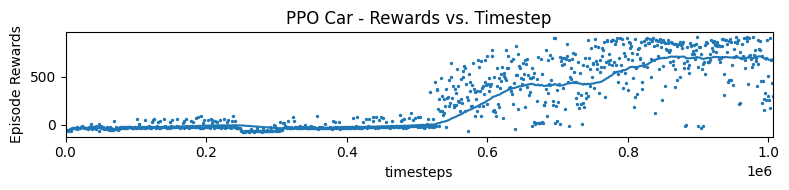

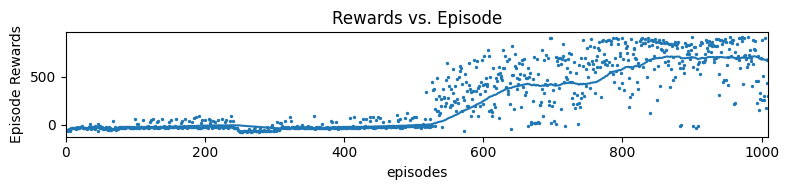

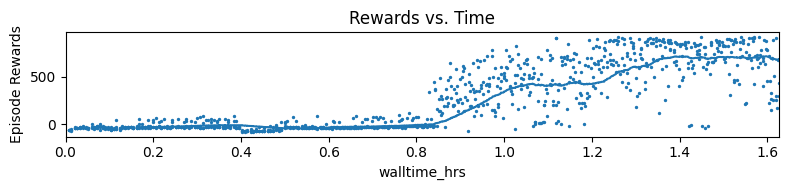

In [4]:
plot_results([log_dir], None, results_plotter.X_TIMESTEPS, "PPO Car - Rewards vs. Timestep")

plot_results([log_dir], None, results_plotter.X_EPISODES, "Rewards vs. Episode")

plot_results([log_dir], None, results_plotter.X_WALLTIME, "Rewards vs. Time")


## Visualizing RL Model Metrics

Use tensorboard in terminal to visualize model training metrics. This should be done on the directory of model_log_dir.

In [ ]:
df = pd.read_csv(f'{model_log_dir}/progress.csv')
print(df.head())

   rollout/ep_rew_mean  time/iterations  time/fps  rollout/ep_len_mean  \
0           -57.089206                1       186               1000.0   
1           -46.189474                2       180               1000.0   
2           -40.326325                3       178               1000.0   
3           -39.364842                4       177               1000.0   
4           -37.152092                5       176               1000.0   

   time/time_elapsed  time/total_timesteps  train/approx_kl  train/clip_range  \
0                 43                  8192              NaN               NaN   
1                 90                 16384         0.012295               0.2   
2                137                 24576         0.015318               0.2   
3                185                 32768         0.019453               0.2   
4                231                 40960         0.028317               0.2   

   train/n_updates  train/policy_gradient_loss  train/learning_rate 

## Load model after training 

In [ ]:
model = PPO.load(model_file)
pprint.pprint(model.__dict__)

config = {
    "learning_rate": model.learning_rate,
    "n_steps": model.n_steps,
    "batch_size": model.batch_size,
    "n_epochs": model.n_epochs,
    "gamma": model.gamma,
    "gae_lambda": model.gae_lambda,
    "clip_range": model.clip_range,
    "ent_coef": model.ent_coef,
    "vf_coef": model.vf_coef,
    "max_grad_norm": model.max_grad_norm,
    "policy": model.policy.__class__.__name__,
    "policy_kwargs": model.policy_kwargs,
}

# with open(f"./ppo_baseline/{model_dir}/baseline_model.json", "w") as f:
#     json.dump(config, f, indent=4, default=str)

{'_current_progress_remaining': -0.007616000000000067,
 '_custom_logger': False,
 '_episode_num': 0,
 '_last_episode_starts': array([False, False, False, False]),
 '_last_obs': array([[[[100, 100, 100, ..., 100, 100, 100],
         [100, 100, 100, ..., 100, 100, 100],
         [100, 100, 100, ..., 100, 100, 100],
         ...,
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0]],

        [[202, 202, 202, ..., 202, 202, 202],
         [202, 202, 202, ..., 202, 202, 202],
         [202, 202, 202, ..., 202, 202, 202],
         ...,
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,   0]],

        [[100, 100, 100, ..., 100, 100, 100],
         [100, 100, 100, ..., 100, 100, 100],
         [100, 100, 100, ..., 100, 100, 100],
         ...,
         [  0,   0,   0, ...,   0,   0,   0],
         [  0,   0,   0, ...,   0,   0,  

## Model Evalulation Setup

In [15]:
eval_env = gym.make(
    "CarRacing-v3",
    continuous=False,
    render_mode="human",
)

In [ ]:
# evaluates rewards across specified eval episodes 
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=10,
    deterministic=True,
)
print(f"mean_reward={mean_reward:.2f} +/- {std_reward}")

/Users/alvint/Documents/personal_code/lap_zero/venv/lib/python3.9/site-packages/stable_baselines3/common/evaluation.py:70: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
# see it in action! 
total_rewards = []
completion_results = []

num_episodes = 5

for episode in range(num_episodes):

    print("episode: ", episode)
    obs, info = eval_env.reset()

    episode_reward = 0
    done = False

    while not done:
        action, _ = model.predict(obs, deterministic=True)

        obs, reward, terminated, truncated, info = eval_env.step(action)

        episode_reward += reward
        done = terminated or truncated

    total_rewards.append(episode_reward)

    completion_results.append(episode_reward > 0)

eval_env.close()

episode:  0
episode:  1
episode:  2


KeyboardInterrupt: 

: 